# 02 — Modèle 61 Coupes d'un Coup (Conv1D + Attention MIL, Binaire)

**Objectif :** Prendre **les 61 coupes consécutives (`slice 100 → 160`) d'un volume IRM en une seule entrée** pour prédire une **probabilité binaire unique `P(Demented)`** (malade vs non malade), puis comparer directement les performances avec la baseline 2D sur **exactement le même split patient**.

### Architecture retenue (adaptée à 347 patients & 7,4 Go RAM)
1. **Extracteur 2D** : on réutilise la couche `slice_embedding` (128 dims) du CNN 2D entraîné dans le notebook 01 pour encoder chaque volume MPR en une séquence ordonnée **`(61, 128)`**.
2. **Modèle Volume 61 coupes (`Conv1D + Gated Attention MIL`)** :
   - Des convolutions **1D le long de l'axe Z (profondeur des 61 coupes)** capturent la continuité anatomique 3D entre coupes adjacentes.
   - Un bloc **Gated Attention Pooling (MIL)** apprend automatiquement un poids d'importance $\alpha_t$ pour chacune des 61 coupes ($\sum_{t=1}^{61} \alpha_t = 1$), au lieu d'une simple moyenne uniforme.
   - Une tête binaire renvoie la probabilité **`P(malade)`** pour l'ensemble du volume.
3. **Interprétabilité** : visualisation du profil d'attention sur les coupes `100 → 160` pour identifier les zones cérébrales les plus déterminantes.


## 1. Configuration, Chargement du Split & Extraction des Embeddings `(61, 128)`


In [1]:
import os
import time
import warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    balanced_accuracy_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

DATA_DIR = Path("/home/timba/Téléchargements/Data")
OUT_DIR = DATA_DIR / "artifacts_modeling"
IMG_H, IMG_W = 96, 192
N_SLICES = 61

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

DEVICE = "/XPU:0" if tf.config.list_physical_devices("XPU") else ("/GPU:0" if tf.config.list_physical_devices("GPU") else "/CPU:0")
print(f"TensorFlow : {tf.__version__} | Périphérique : {DEVICE}")

# Chargement du split strict par patient généré dans le notebook 01
df = pd.read_csv(OUT_DIR / "splits_binary.csv").sort_values(["volume_id", "slice_idx"]).reset_index(drop=True)
print(f"Images : {len(df):,} | Volumes : {df['volume_id'].nunique():,} | Patients : {df['subject_id'].nunique()}")


2026-11-22 13:04:05.717370: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-22 13:04:05.717411: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-22 13:04:05.729397: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-22 13:04:09.069494: I itex/core/wrapper/itex_gpu_wrapper.cc:38] Intel Extension for Tensorflow* GPU backend is loaded.
2026-11-22 13:04:09.137048: I itex/core/devices/gpu/itex_gpu_runtime.cc:130] Selected platform: Intel(R) oneAPI Unified Runtime over Level-Zero
2026-11-22 13:04:09.137078: I itex/core/devices/gpu/itex_gpu_runtime.cc:155] number of sub-dev

TensorFlow : 2.15.1 | Périphérique : /XPU:0
Images : 86,437 | Volumes : 1,417 | Patients : 347


In [2]:
# Extraction (ou rechargement si cache plus récent que baseline_2d_cnn.keras)
base_model_path = OUT_DIR / "baseline_2d_cnn.keras"
emb_cache = OUT_DIR / "volume_embeddings_61xD.npz"
meta_cache = OUT_DIR / "volume_meta.csv"

cache_fresh = (
    emb_cache.exists()
    and meta_cache.exists()
    and emb_cache.stat().st_mtime >= base_model_path.stat().st_mtime
)

if cache_fresh:
    print("♻️ Rechargement des embeddings 61×D depuis le cache à jour...")
    X_vols = np.load(emb_cache)["X_vols"]
    vol_meta = pd.read_csv(meta_cache)
else:
    print("🔄 Extraction des embeddings slice_embedding sur les 86 437 coupes...")
    t0 = time.time()
    base_model = keras.models.load_model(base_model_path)
    extractor = keras.Model(
        inputs=base_model.input,
        outputs=base_model.get_layer("slice_embedding").output,
        name="Slice_Embedding_Extractor",
    )

    def load_img_only(path):
        raw = tf.io.read_file(path)
        img = tf.io.decode_jpeg(raw, channels=1)
        img = tf.image.resize(img, [IMG_H, IMG_W], method="bilinear")
        return tf.cast(img, tf.float32) / 255.0

    ds_all = (
        tf.data.Dataset.from_tensor_slices(df["filepath"].values)
        .map(load_img_only, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(128)
        .prefetch(tf.data.AUTOTUNE)
    )
    with tf.device(DEVICE):
        all_embs = extractor.predict(ds_all, verbose=0).astype(np.float32)

    # Regroupement en tenseur (N_volumes, 61, 128) dans l'ordre exact slice_idx 100..160
    n_vols = len(df) // N_SLICES
    assert len(df) == n_vols * N_SLICES
    X_vols = all_embs.reshape(n_vols, N_SLICES, -1)

    vol_meta = (
        df.groupby("volume_id", sort=False, as_index=False)
        .agg(
            subject_id=("subject_id", "first"),
            label_4cls=("label_4cls", "first"),
            target=("target", "first"),
            split=("split", "first"),
        )
    )
    assert len(vol_meta) == n_vols
    np.savez_compressed(emb_cache, X_vols=X_vols)
    vol_meta.to_csv(meta_cache, index=False)
    print(f"✅ Embeddings extraits en {time.time()-t0:.1f}s -> shape = {X_vols.shape} ({X_vols.nbytes/1e6:.1f} Mo)")

print("Répartition des volumes par split :")
display(vol_meta.groupby(["split", "target"]).size().unstack(fill_value=0))


🔄 Extraction des embeddings slice_embedding sur les 86 437 coupes...
✅ Embeddings extraits en 284.9s -> shape = (1417, 61, 64) (22.1 Mo)
Répartition des volumes par split :


target,0,1
split,,
test,170,50
train,764,220
val,168,45


## 2. Architecture du Modèle 61 Coupes (`Conv1D + Gated Attention MIL`)

Le modèle prend un tenseur **`(61, 128)`** (toutes les coupes d'un volume d'un seul coup) :
1. **Standardisation** des embeddings (fit sur le train uniquement) + léger bruit gaussien en entraînement pour régulariser.
2. **Encodeur de profondeur (Conv1D sur l'axe des 61 coupes)** : 2 couches `Conv1D(kernel_size=3)` avec connexion résiduelle pour modéliser les transitions anatomiques entre coupes voisines.
3. **Gated Attention Pooling (Ilse et al., 2018)** : calcule un score d'attention pour chacune des 61 coupes :
   $$a_t = \text{softmax}_t\Big(w^\top (\tanh(V h_t) \odot \sigma(U h_t))\Big)$$
   et agrège le volume par somme pondérée $z = \sum_{t=1}^{61} a_t h_t$.
4. **Sortie binaire** : `Dense(1, activation="sigmoid")` → probabilité unique **`P(Demented)`** pour le volume entier.


In [3]:
# Préparation des tableaux Train / Val / Test (strictement alignés sur splits_binary.csv)
train_m = (vol_meta["split"] == "train").values
val_m = (vol_meta["split"] == "val").values
test_m = (vol_meta["split"] == "test").values

X_train, y_train = X_vols[train_m], vol_meta.loc[train_m, "target"].values.astype(np.float32)
X_val, y_val = X_vols[val_m], vol_meta.loc[val_m, "target"].values.astype(np.float32)
X_test, y_test = X_vols[test_m], vol_meta.loc[test_m, "target"].values.astype(np.float32)

# Standardisation des features (calculée uniquement sur Train)
feat_mean = X_train.mean(axis=(0, 1), keepdims=True)
feat_std = X_train.std(axis=(0, 1), keepdims=True) + 1e-6
X_train = (X_train - feat_mean) / feat_std
X_val = (X_val - feat_mean) / feat_std
X_test = (X_test - feat_mean) / feat_std

# Class weights au niveau volume
n_neg, n_pos = (y_train == 0).sum(), (y_train == 1).sum()
class_weight_vol = {0: len(y_train) / (2.0 * n_neg), 1: len(y_train) / (2.0 * n_pos)}
print(f"Volumes -> Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")
print(f"Class weights (volumes) : {class_weight_vol}")

class GatedAttentionPooling(layers.Layer):
    def __init__(self, attn_dim=16, l2_reg=1e-2, **kwargs):
        super().__init__(**kwargs)
        self.attn_dim = attn_dim
        self.l2_reg = l2_reg
        reg = keras.regularizers.l2(l2_reg)
        self.V = layers.Dense(attn_dim, activation="tanh", kernel_regularizer=reg)
        self.U = layers.Dense(attn_dim, activation="sigmoid", kernel_regularizer=reg)
        self.w = layers.Dense(1, kernel_regularizer=reg)

    def call(self, inputs):
        # inputs: (B, 61, D)
        scores = self.w(self.V(inputs) * self.U(inputs))  # (B, 61, 1)
        weights = tf.nn.softmax(scores, axis=1)           # (B, 61, 1)
        context = tf.reduce_sum(weights * inputs, axis=1) # (B, D)
        return context, tf.squeeze(weights, axis=-1)      # (B, D), (B, 61)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"attn_dim": self.attn_dim, "l2_reg": self.l2_reg})
        return cfg

def build_volume_61_model(n_slices=N_SLICES, emb_dim=64):
    # Architecture ultra-compacte (< 6 000 params) + forte régularisation anti-overfitting (242 patients en train)
    reg = keras.regularizers.l2(1e-2)
    inp = keras.Input(shape=(n_slices, emb_dim), name="volume_61_slices")

    # Slice Dropout : masque aléatoirement 25% des 61 coupes entières à chaque step
    x = layers.Dropout(0.25, noise_shape=(None, n_slices, 1), name="slice_dropout")(inp)
    x = layers.SpatialDropout1D(0.30, name="feat_dropout")(x)

    # Un seul bloc Conv1D léger le long de l'axe Z (profondeur des 61 coupes)
    h = layers.Conv1D(24, kernel_size=3, padding="same", activation="relu", kernel_regularizer=reg, name="conv1d_z")(x)
    h = layers.BatchNormalization()(h)
    h = layers.Dropout(0.40)(h)

    # Agrégation des 61 coupes par Gated Attention MIL compacte
    context, attn_weights = GatedAttentionPooling(attn_dim=16, l2_reg=1e-2, name="gated_attention")(h)
    z = layers.Dropout(0.50)(context)
    out = layers.Dense(1, activation="sigmoid", kernel_regularizer=reg, name="prob_demented")(z)

    train_model = keras.Model(inp, out, name="Volume_61Slices_MIL_Compact")
    attn_model = keras.Model(inp, [out, attn_weights], name="Volume_61Slices_MIL_WithAttn")
    return train_model, attn_model

vol_model, vol_attn_model = build_volume_61_model(N_SLICES, X_train.shape[-1])
vol_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.BinaryCrossentropy(label_smoothing=0.05),
    metrics=[
        keras.metrics.AUC(name="roc_auc", curve="ROC"),
        keras.metrics.AUC(name="pr_auc", curve="PR"),
    ],
)
vol_model.summary()


Volumes -> Train: 984 | Val: 213 | Test: 220
Class weights (volumes) : {0: 0.643979057591623, 1: 2.2363636363636363}
Model: "Volume_61Slices_MIL_Compact"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 volume_61_slices (InputLay  [(None, 61, 64)]          0         
 er)                                                             
                                                                 
 slice_dropout (Dropout)     (None, 61, 64)            0         
                                                                 
 feat_dropout (SpatialDropo  (None, 61, 64)            0         
 ut1D)                                                           
                                                                 
 conv1d_z (Conv1D)           (None, 61, 24)            4632      
                                                                 
 batch_normalization (Batch  (None, 61, 24)           

## 3. Entraînement du Modèle 61 Coupes


Epoch 1/50
31/31 - 6s - loss: 1.3739 - roc_auc: 0.7619 - pr_auc: 0.4838 - val_loss: 1.3206 - val_roc_auc: 0.8773 - val_pr_auc: 0.6067 - lr: 3.0000e-04 - 6s/epoch - 184ms/step
Epoch 2/50
31/31 - 1s - loss: 1.2311 - roc_auc: 0.8603 - pr_auc: 0.6244 - val_loss: 1.2424 - val_roc_auc: 0.8835 - val_pr_auc: 0.6366 - lr: 3.0000e-04 - 591ms/epoch - 19ms/step
Epoch 3/50
31/31 - 1s - loss: 1.1789 - roc_auc: 0.8654 - pr_auc: 0.6299 - val_loss: 1.1760 - val_roc_auc: 0.8874 - val_pr_auc: 0.6651 - lr: 3.0000e-04 - 640ms/epoch - 21ms/step
Epoch 4/50
31/31 - 1s - loss: 1.1239 - roc_auc: 0.8750 - pr_auc: 0.6346 - val_loss: 1.1184 - val_roc_auc: 0.8884 - val_pr_auc: 0.6645 - lr: 3.0000e-04 - 641ms/epoch - 21ms/step
Epoch 5/50
31/31 - 1s - loss: 1.0783 - roc_auc: 0.8736 - pr_auc: 0.6423 - val_loss: 1.0704 - val_roc_auc: 0.8929 - val_pr_auc: 0.6726 - lr: 3.0000e-04 - 650ms/epoch - 21ms/step
Epoch 6/50
31/31 - 1s - loss: 1.0412 - roc_auc: 0.8773 - pr_auc: 0.6293 - val_loss: 1.0388 - val_roc_auc: 0.8925 - va

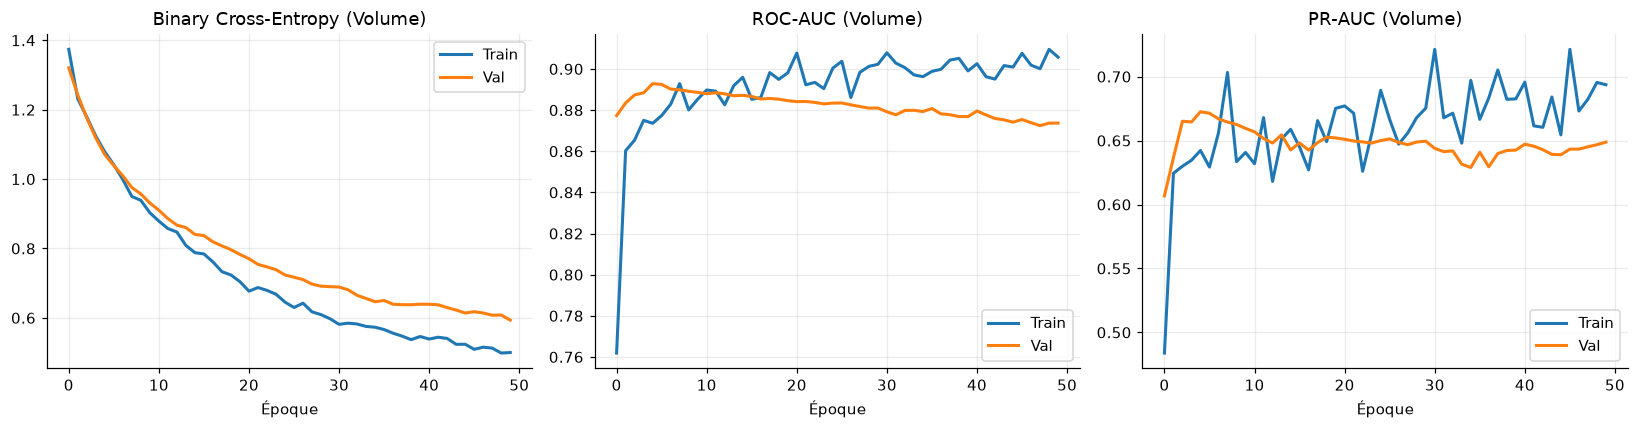

In [4]:
vol_model_path = OUT_DIR / "volume_61_mil.keras"

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(vol_model_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=0,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=4,
        min_lr=1e-5,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=10,
        restore_best_weights=True,
        verbose=1,
    ),
]

t0 = time.time()
history = vol_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    batch_size=32,
    epochs=50,
    class_weight=class_weight_vol,
    callbacks=callbacks,
    verbose=2,
)
print(f"\n✅ Entraînement terminé en {time.time()-t0:.1f}s.")

# Courbes d'apprentissage
hist = history.history
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric, title in zip(
    axes,
    ["loss", "roc_auc", "pr_auc"],
    ["Binary Cross-Entropy (Volume)", "ROC-AUC (Volume)", "PR-AUC (Volume)"],
):
    ax.plot(hist[metric], label="Train", lw=2)
    ax.plot(hist[f"val_{metric}"], label="Val", lw=2)
    ax.set_title(title)
    ax.set_xlabel("Époque")
    ax.legend()
plt.tight_layout()
plt.show()


## 4. Évaluation sur le Test Set & Comparaison Directe avec la Baseline 2D

Comparons sur **exactement les mêmes patients de Test** :
- **Baseline 2D** : prédiction coupe par coupe, puis moyenne simple des 61 coupes.
- **Modèle 61 coupes (Conv1D + Attention MIL)** : ingestion simultanée des 61 coupes → 1 probabilité binaire par volume (puis moyenne sur les volumes d'un même patient).


In [5]:
# Prédictions + poids d'attention sur Val et Test
val_probs_61, val_attn = vol_attn_model.predict(X_val, verbose=0)
test_probs_61, test_attn = vol_attn_model.predict(X_test, verbose=0)
val_probs_61 = val_probs_61.ravel()
test_probs_61 = test_probs_61.ravel()

val_vol_df = vol_meta[val_m].copy().reset_index(drop=True)
val_vol_df["pred_61"] = val_probs_61

test_vol_df = vol_meta[test_m].copy().reset_index(drop=True)
test_vol_df["pred_61"] = test_probs_61

# Calibration du seuil sur Validation (niveau patient, indice de Youden)
val_pat_61 = val_vol_df.groupby("subject_id", as_index=False).agg(target=("target", "first"), pred_61=("pred_61", "mean"))
fpr_v, tpr_v, thr_v = roc_curve(val_pat_61["target"], val_pat_61["pred_61"])
best_thr_61 = float(thr_v[np.argmax(tpr_v - fpr_v)])

# Chargement des prédictions de la Baseline 2D pour comparaison directe
b2d_val = pd.read_csv(OUT_DIR / "baseline_2d_val_preds.csv")
b2d_test = pd.read_csv(OUT_DIR / "baseline_2d_test_preds.csv")
b2d_val_pat = b2d_val.groupby("subject_id", as_index=False).agg(target=("target", "first"), pred_prob=("pred_prob", "mean"))
fpr_b, tpr_b, thr_b = roc_curve(b2d_val_pat["target"], b2d_val_pat["pred_prob"])
best_thr_2d = float(thr_b[np.argmax(tpr_b - fpr_b)])

b2d_test_vol = b2d_test.groupby("volume_id", as_index=False).agg(target=("target", "first"), pred_prob=("pred_prob", "mean"))
b2d_test_pat = b2d_test.groupby("subject_id", as_index=False).agg(target=("target", "first"), pred_prob=("pred_prob", "mean"))

test_pat_61 = test_vol_df.groupby("subject_id", as_index=False).agg(
    label_4cls=("label_4cls", "first"), target=("target", "first"), pred_61=("pred_61", "mean")
)

def metrics_row(name, y_true, y_prob, thr):
    y_pred = (y_prob >= thr).astype(int)
    return {
        "Modèle / Niveau": name,
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
        "F1 (Malade)": f1_score(y_true, y_pred, zero_division=0),
    }

comp_df = pd.DataFrame([
    metrics_row("Baseline 2D — Volume (moy. 61 coupes)", b2d_test_vol["target"], b2d_test_vol["pred_prob"], best_thr_2d),
    metrics_row("Modèle 61 coupes (MIL) — Volume", test_vol_df["target"], test_vol_df["pred_61"], best_thr_61),
    metrics_row("Baseline 2D — Patient", b2d_test_pat["target"], b2d_test_pat["pred_prob"], best_thr_2d),
    metrics_row("Modèle 61 coupes (MIL) — Patient", test_pat_61["target"], test_pat_61["pred_61"], best_thr_61),
])
print(f"Seuils calibrés sur Val -> Baseline 2D : {best_thr_2d:.3f} | Modèle 61 coupes : {best_thr_61:.3f}")
display(comp_df.round(4))

y_pat_pred_61 = (test_pat_61["pred_61"] >= best_thr_61).astype(int)
print("\nRapport détaillé — Modèle 61 coupes (Test — niveau Patient) :")
print(classification_report(test_pat_61["target"], y_pat_pred_61, target_names=["Non Demented (0)", "Demented (1)"], digits=3))

test_pat_61["pred"] = y_pat_pred_61
print("Taux de détection par sous-classe clinique (Test — niveau Patient) :")
display(
    test_pat_61.groupby("label_4cls")
    .agg(n_patients=("subject_id", "count"), proba_moyenne=("pred_61", "mean"), taux_detecte_malade=("pred", "mean"))
    .round(3)
)


Seuils calibrés sur Val -> Baseline 2D : 0.268 | Modèle 61 coupes : 0.541


,Modèle / Niveau,ROC-AUC,PR-AUC,Balanced Acc,F1 (Malade)
0,Baseline 2D — Volume (moy. 61 coupes),0.9174,0.6149,0.8382,0.6452
1,Modèle 61 coupes (MIL) — Volume,0.8986,0.6589,0.8365,0.6667
2,Baseline 2D — Patient,0.9115,0.6687,0.8250,0.6500
3,Modèle 61 coupes (MIL) — Patient,0.8923,0.6870,0.8240,0.6667



Rapport détaillé — Modèle 61 coupes (Test — niveau Patient) :
                  precision    recall  f1-score   support

Non Demented (0)      0.967     0.725     0.829        40
    Demented (1)      0.522     0.923     0.667        13

        accuracy                          0.774        53
       macro avg      0.744     0.824     0.748        53
    weighted avg      0.858     0.774     0.789        53

Taux de détection par sous-classe clinique (Test — niveau Patient) :


,n_patients,proba_moyenne,taux_detecte_malade
label_4cls,,,
Mild Dementia,4,0.885,1.000
Non Demented,40,0.336,0.275
Very mild Dementia,9,0.764,0.889


## 5. Comparaison Visuelle & Profil d'Attention sur les 61 Coupes (`100 → 160`)


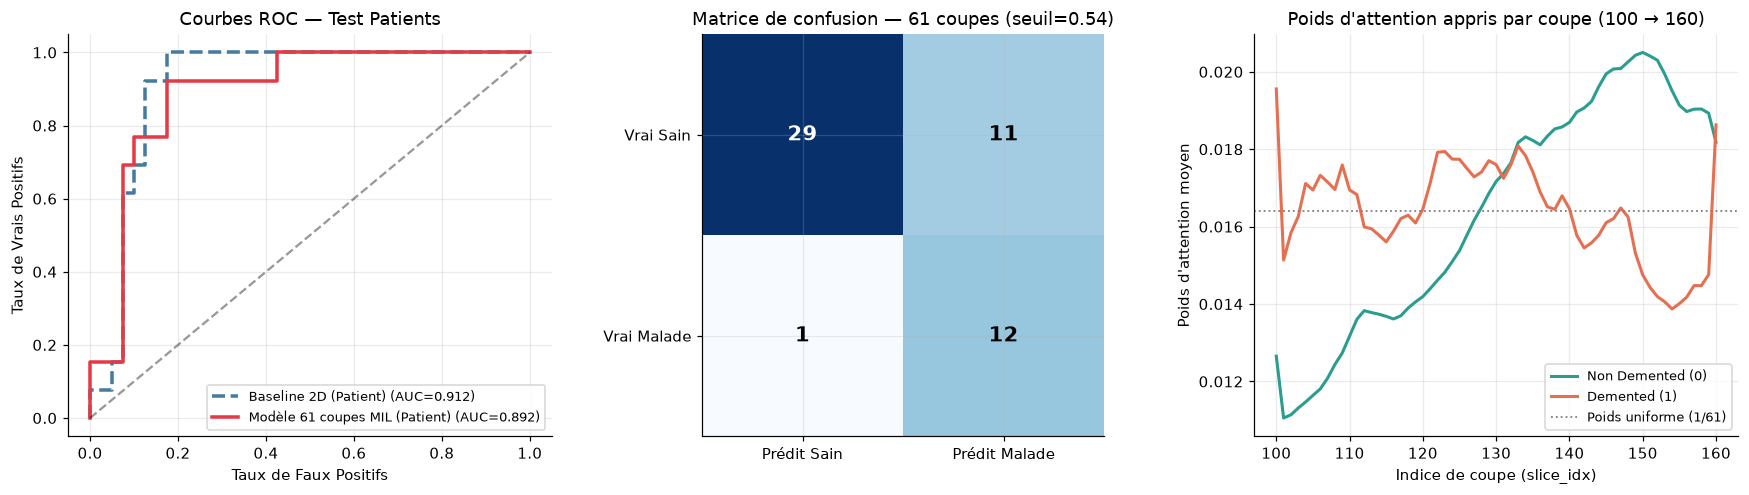

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# 1. Courbe ROC : Baseline 2D vs Modèle 61 coupes (niveau Patient)
for name, y_t, y_p, color, ls in [
    ("Baseline 2D (Patient)", b2d_test_pat["target"], b2d_test_pat["pred_prob"], "#457b9d", "--"),
    ("Modèle 61 coupes MIL (Patient)", test_pat_61["target"], test_pat_61["pred_61"], "#e63946", "-"),
]:
    fpr, tpr, _ = roc_curve(y_t, y_p)
    auc = roc_auc_score(y_t, y_p)
    axes[0].plot(fpr, tpr, color=color, linestyle=ls, lw=2.3, label=f"{name} (AUC={auc:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set_title("Courbes ROC — Test Patients")
axes[0].set_xlabel("Taux de Faux Positifs")
axes[0].set_ylabel("Taux de Vrais Positifs")
axes[0].legend(fontsize=8.5)

# 2. Matrice de confusion — Modèle 61 coupes (Patients)
cm = confusion_matrix(test_pat_61["target"], y_pat_pred_61)
axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks([0, 1])
axes[1].set_yticks([0, 1])
axes[1].set_xticklabels(["Prédit Sain", "Prédit Malade"])
axes[1].set_yticklabels(["Vrai Sain", "Vrai Malade"])
axes[1].set_title(f"Matrice de confusion — 61 coupes (seuil={best_thr_61:.2f})")
for i in range(2):
    for j in range(2):
        axes[1].text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14, fontweight="bold",
                     color="white" if cm[i, j] > cm.max()/2 else "black")

# 3. Profil d'attention moyen sur les 61 coupes (100 -> 160)
slices_axis = np.arange(100, 161)
attn_healthy = test_attn[test_vol_df["target"].values == 0].mean(axis=0)
attn_demented = test_attn[test_vol_df["target"].values == 1].mean(axis=0)
axes[2].plot(slices_axis, attn_healthy, label="Non Demented (0)", color="#2a9d8f", lw=2)
axes[2].plot(slices_axis, attn_demented, label="Demented (1)", color="#e76f51", lw=2)
axes[2].axhline(1.0 / N_SLICES, color="gray", linestyle=":", lw=1.2, label="Poids uniforme (1/61)")
axes[2].set_title("Poids d'attention appris par coupe (100 → 160)")
axes[2].set_xlabel("Indice de coupe (slice_idx)")
axes[2].set_ylabel("Poids d'attention moyen")
axes[2].legend(fontsize=8.5)

plt.tight_layout()
plt.show()
